<a href="https://colab.research.google.com/github/lopezreyesleonardoa-sketch/Equipo-P-IA/blob/main/Actividad_Fundamental_2_PPIA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Actividad Fundamental 2**

Equipo:

Cristofer Jair Zuñiga Escobar 2189229

Leonardo Alfredo López Reyes 2181755

Diego Otoniel Cantu Cantu 2208782

Angel Gabriel Alonso Navarro 2116170

Alexis Eduardo Puente Mendoza 2188873

## **Ejercicio 1 .-  Uso de Pandas, Matplotlib, Numpy**

### **Ejercicio 1.1.- Limpieza y Manipulación con Pandas**

**Objetivo: Cargar los datos, entender su estructura y realizar filtrados básicos.**

Descripción: se importa el dataset de calidad del vino tinto desde una URL y se muestran sus primeras cinco filas y su resumen estadístico. Después, se identifican y eliminan los valores nulos, se crea la columna is_good para clasificar los vinos con calidad superior a 6 y, finalmente, se filtran los vinos cuyo nivel de alcohol es superior al 11%.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [12]:
#1. Importa el dataset directamente desde una URL.
print("*Importación del Dataset*")
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
df = pd.read_csv(url, sep=';')
print("Dataset cargado correctamente:")

#2. Muestra las primeras 5 filas y el resumen estadístico (`describe()`).
print("*Primeras 5 filas y Resumen estadístico*")
print(df.head())
print(df.describe())

#3. Identifica si existen valores nulos y elimínalos.
print("*Verificación y eliminación de valores nulos*")
print(df.isnull().sum())
df = df.dropna()
print(df.isnull().sum())

#4. Crea una nueva columna llamada `is_good` que sea **1** si la `quality` es mayor a 6, y **0** en caso contrario.
print("*Is good*")
df['is_good'] = (df['quality'] > 6).astype(int)
print (df['is_good'])

#5. Filtra el DataFrame para mostrar solo los vinos con un nivel de alcohol superior al 11%
print("*Vinos con nivel de alcohol superior al 11%*")
alcohol_superior = df[df['alcohol'] > 11]
print(alcohol_superior)

*Importación del Dataset*
Dataset cargado correctamente:
*Primeras 5 filas y Resumen estadístico*
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51    

### **Ejercicio 1.2.- Operaciones Matemáticas con NumPy**

**Objetivo: Convertir los datos a matrices y realizar cálculos de bajo nivel que la IA necesita.**

Descripción: se convierten las columnas de características del dataset en una matriz de NumPy llamada X, excluyendo la columna quality. Después, se calcula la media y la desviación estándar de cada característica y se aplica manualmente la normalización Z-Score para estandarizar los datos.

In [14]:
#1. Convierte las columnas de características (features) en una matriz de NumPy llamada `X`.
print("*Matriz de NumPy*")
features = df.columns.drop('quality')
X = np.array(df[features])
print(X)

#2. Calcula la **media** y la **desviación estándar** de cada columna utilizando únicamente funciones de NumPy (`np.mean`, `np.std`).
print("*Media y desviación estándar*")
media = np.mean(X, axis=0)
dvs = np.std(X, axis=0)
print("Media:", media)
print("Desviación estándar:", dvs)

#3. **Normalización Z-Score:** Implementa manualmente la fórmula para normalizar los datos.
print("*Normalización de datos*")
norm = (X - media) / dvs
print(norm)

*Matriz de NumPy*
[[ 7.4    0.7    0.    ...  0.56   9.4    0.   ]
 [ 7.8    0.88   0.    ...  0.68   9.8    0.   ]
 [ 7.8    0.76   0.04  ...  0.65   9.8    0.   ]
 ...
 [ 6.3    0.51   0.13  ...  0.75  11.     0.   ]
 [ 5.9    0.645  0.12  ...  0.71  10.2    0.   ]
 [ 6.     0.31   0.47  ...  0.66  11.     0.   ]]
*Media y desviación estándar*
Media: [ 8.31963727  0.52782051  0.27097561  2.5388055   0.08746654 15.87492183
 46.46779237  0.99674668  3.3111132   0.65814884 10.42298311  0.13570982]
Desviación estándar: [1.74055180e+00 1.79003704e-01 1.94740214e-01 1.40948711e+00
 4.70505826e-02 1.04568856e+01 3.28850367e+01 1.88674370e-03
 1.54338181e-01 1.69453967e-01 1.06533430e+00 3.42480166e-01]
*Normalización de datos*
[[-0.52835961  0.96187667 -1.39147228 ... -0.57920652 -0.96024611
  -0.39625599]
 [-0.29854743  1.96744245 -1.39147228 ...  0.1289504  -0.58477711
  -0.39625599]
 [-0.29854743  1.29706527 -1.18607043 ... -0.04808883 -0.58477711
  -0.39625599]
 ...
 [-1.1603431  -0.099

### **Ejercicio 1.3.- Visualización de Insights con Matplotlib**

**Objetivo: Comunicar visualmente las correlaciones y distribuciones de los datos.**

Descripción: en base al dataset de calidad del vino tinto se generan tres gráficos para analizar sus características: un histograma para observar la distribución del nivel de alcohol, un gráfico de dispersión para ver la relación entre el pH y la acidez fija, y un diagrama de cajas para comparar los niveles de alcohol según la calidad del vino.

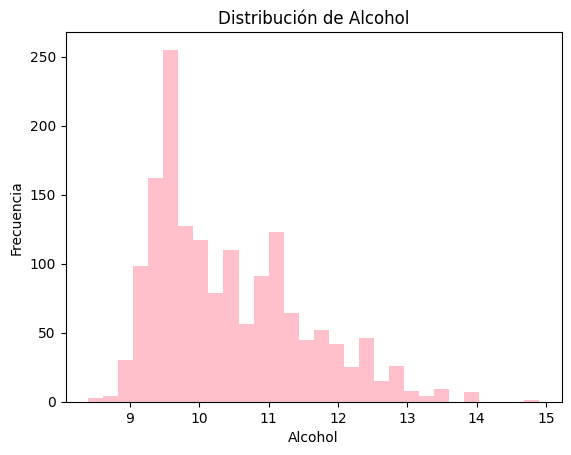

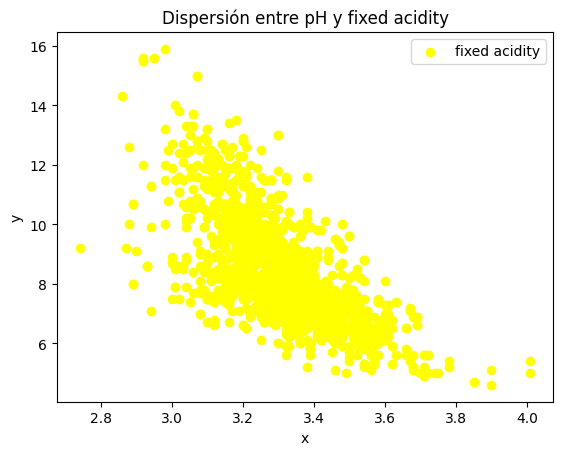

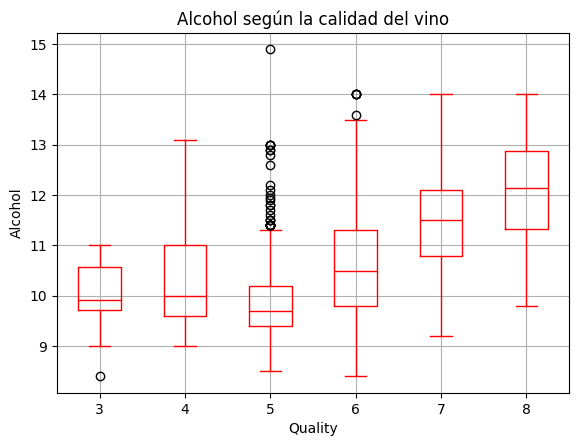

In [7]:

    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
    df = pd.read_csv(url, sep=';')

#1. histograma de la variable `alcohol` para ver su distribución.
datos = df['alcohol']
plt.hist(datos, bins=30, color='pink')
plt.xlabel('Alcohol')
plt.ylabel('Frecuencia')
plt.title('Distribución de Alcohol')
plt.show()

#2. **Scatter Plot:** Realiza un gráfico de dispersión entre `pH` y `fixed acidity`.
x=df['pH']
y=df['fixed acidity']
datos = df[['pH', 'fixed acidity']]
plt.scatter(x, y, color='yellow', label="fixed acidity")
plt.title("Dispersión entre pH y fixed acidity")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

#3. **Boxplot:** Genera un gráfico de cajas que compare el nivel de `alcohol` según la `quality`.

datos = df[['quality', 'alcohol']]
df.boxplot(column='alcohol', by='quality', color='red')
plt.title("Alcohol según la calidad del vino")
plt.xlabel("Quality")
plt.ylabel("Alcohol")
plt.suptitle("")
plt.show()

## **Ejercicio 2 .- Uso de Pandas, Matplotlib, Numpy**

### **Ejercicio 2.1.- Análisis Exploratorio con Pandas**

**Objetivo: Limpieza de datos reales (que suelen venir con errores o huecos).**


Descripción: se carga el dataset de los pingüinos de Palmer y se identifican y eliminan las filas que contienen valores nulos. Después, se calcula la masa corporal promedio agrupando los pingüinos por especie e isla y se crea un subconjunto que contiene únicamente pingüinos de la especie Gentoo con un peso superior a 5000 gramos.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [8]:
#1. Carga el dataset de Pingüinos de Palmer (abajo en el bloque de código aparece como descargarlo).
print("*Carga del Dataset*")
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"
df = pd.read_csv(url)
print("Dataset cargado correctamente:")
#2. **Manejo de Nulos:** Identifica cuántas filas tienen valores `NaN`. Elimina aquellas filas donde falten datos críticos (como el peso o el tamaño del pico).
print("*Filas de valores Nulos y eliminación de filas donde falten datos críticos*")
print(df.isnull().sum())
df = df.dropna()
print(df.isnull().sum())

#3. **Agrupación:** Calcula la masa corporal (`body_mass_g`) promedio por cada **especie** y por **isla**.
print("*Masa corporal promedio por cada especie y por isla*")
media = df.groupby(['species', 'island'])['body_mass_g'].mean()
print(media)

#4. **Segmentación:** Crea un subconjunto de datos que solo contenga a los pingüinos de la especie "Gentoo" que pesen más de 5000g.
print("*Pingüinos de la especie Gentoo*")
gentoo = df[(df['species'] == 'Gentoo') & (df['body_mass_g'] > 5000)]
print(gentoo)

*Carga del Dataset*
Dataset cargado correctamente:
*Filas de valores Nulos y eliminación de filas donde falten datos críticos*
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64
*Masa corporal promedio por cada especie y por isla*
species    island   
Adelie     Biscoe       3709.659091
           Dream        3701.363636
           Torgersen    3708.510638
Chinstrap  Dream        3733.088235
Gentoo     Biscoe       5092.436975
Name: body_mass_g, dtype: float64
*Pingüinos de la especie Gentoo*
    species  island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
221  Gentoo  Biscoe            50.0           16.3              230.0   
223  Gentoo  Biscoe            50.0           15.2 

### **Ejercicio 2.2.- Procesamiento de Señales con NumPy**

**Objetivo: Manipulación de dimensiones y cálculos estadísticos rápidos.**


Descripción: se extraen las columnas correspondientes al largo y al alto del pico de los pingüinos y se convierten en una matriz de NumPy de N×2. Después, se calcula la proporción entre ambas medidas, se identifican los valores atípicos del largo del pico que superan dos desviaciones estándar respecto a la media y se extraen los datos de las posiciones pares del array original.

In [10]:
#1. Extrae las columnas `bill_length_mm` (largo) y `bill_depth_mm` (alto) y conviértelas en una matriz de NumPy de $N \times 2$.
print("*Matriz Numpy*")
datos = df[['bill_length_mm', 'bill_depth_mm']].values
print(datos)

#2. **Cálculo de Proporción:** Crea un nuevo array que sea el resultado de dividir el largo entre el alto para cada pingüino.
print("*Array del largo entre el alto de cada pingüino*")
proporcion = datos[:, 0] / datos[:, 1]
print(proporcion)

#3. **Detección de Outliers:** Utiliza una función de NumPy para encontrar qué pingüinos tienen un largo de pico que esté a más de 2 desviaciones estándar de la media del grupo.
print("*Pingüinos con un largo de pico que esté a dos desviaciones estándar de la media del grupo*")
media = np.mean(datos[:, 0])
dvs = np.std(datos[:, 0])
outliers = datos[(datos[:, 0] > media + 2 * dvs) | (datos[:, 0] < media - 2 * dvs)]
print(outliers)

#4. **Slicing:** Extrae solo los datos de los pingüinos que están en las posiciones pares del array original.
print("*Datos de pingüinos que están en las posiciones pared del Array original*")
pares = datos[::2]
print(pares)

*Matriz Numpy*
[[39.1 18.7]
 [39.5 17.4]
 [40.3 18. ]
 [36.7 19.3]
 [39.3 20.6]
 [38.9 17.8]
 [39.2 19.6]
 [41.1 17.6]
 [38.6 21.2]
 [34.6 21.1]
 [36.6 17.8]
 [38.7 19. ]
 [42.5 20.7]
 [34.4 18.4]
 [46.  21.5]
 [37.8 18.3]
 [37.7 18.7]
 [35.9 19.2]
 [38.2 18.1]
 [38.8 17.2]
 [35.3 18.9]
 [40.6 18.6]
 [40.5 17.9]
 [37.9 18.6]
 [40.5 18.9]
 [39.5 16.7]
 [37.2 18.1]
 [39.5 17.8]
 [40.9 18.9]
 [36.4 17. ]
 [39.2 21.1]
 [38.8 20. ]
 [42.2 18.5]
 [37.6 19.3]
 [39.8 19.1]
 [36.5 18. ]
 [40.8 18.4]
 [36.  18.5]
 [44.1 19.7]
 [37.  16.9]
 [39.6 18.8]
 [41.1 19. ]
 [36.  17.9]
 [42.3 21.2]
 [39.6 17.7]
 [40.1 18.9]
 [35.  17.9]
 [42.  19.5]
 [34.5 18.1]
 [41.4 18.6]
 [39.  17.5]
 [40.6 18.8]
 [36.5 16.6]
 [37.6 19.1]
 [35.7 16.9]
 [41.3 21.1]
 [37.6 17. ]
 [41.1 18.2]
 [36.4 17.1]
 [41.6 18. ]
 [35.5 16.2]
 [41.1 19.1]
 [35.9 16.6]
 [41.8 19.4]
 [33.5 19. ]
 [39.7 18.4]
 [39.6 17.2]
 [45.8 18.9]
 [35.5 17.5]
 [42.8 18.5]
 [40.9 16.8]
 [37.2 19.4]
 [36.2 16.1]
 [42.1 19.1]
 [34.6 17.2]
 [42.9 17.

### **Ejercicio 2.3.- Visualización Científica con Matplotlib**

**Objetivo: Encontrar patrones visuales que separen a las especies.**

Descripción: se carga el dataset de los pingüinos de Palmer y se eliminan las filas con valores nulos. Después, se crean gráficos de dispersión para analizar la relación entre el largo de las aletas y la masa corporal, se diferencian las tres especies mediante colores, se señala al pingüino más pesado con una anotación y se generan dos gráficos adicionales en una misma figura para comparar distintas características físicas.

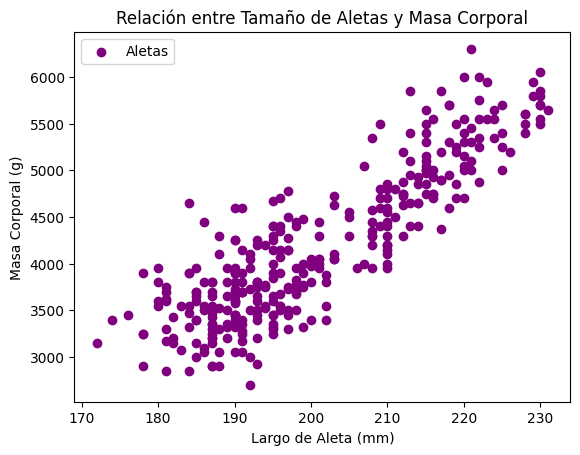

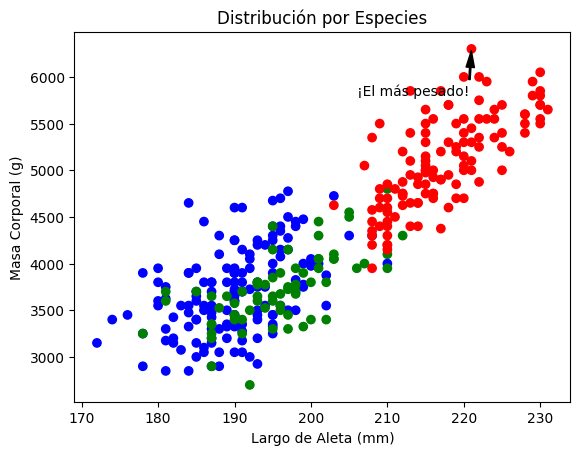

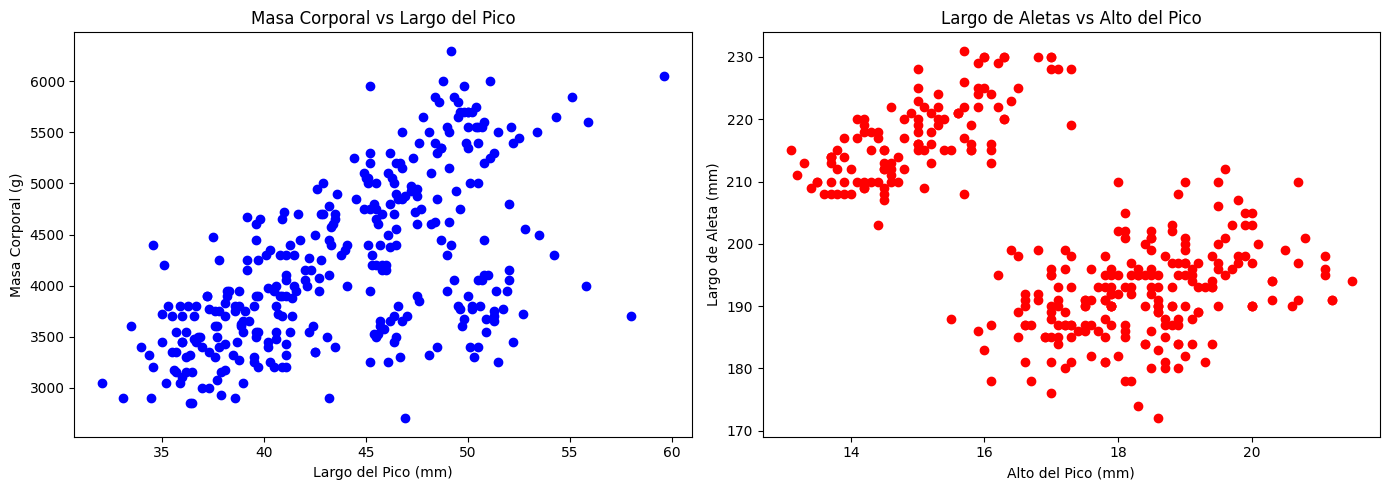

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Volvemos a cargar el dataset de pingüinos específicamente para esta celda para evitar conflictos de variables con el dataset de vinos
url_penguins = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"
df_penguins = pd.read_csv(url_penguins).dropna()

# 1. Scatter Plot: Grafica flipper_length_mm (aletas) en el eje X y body_mass_g en el eje Y.
x = df_penguins['flipper_length_mm']
y = df_penguins['body_mass_g']
plt.scatter(x, y, color='purple', label="Aletas")
plt.title("Relación entre Tamaño de Aletas y Masa Corporal")
plt.xlabel("Largo de Aleta (mm)")
plt.ylabel("Masa Corporal (g)")
plt.legend()
plt.show()

# 2. Codificación de Colores: Usa un color diferente para cada una de las tres especies (Adelie, Chinstrap, Gentoo). Esto ayudará a ver cómo se agrupan naturalmente.
colores = {'Adelie': 'blue', 'Chinstrap': 'green', 'Gentoo': 'red'}
colores_pinguinos = df_penguins['species'].map(colores)
plt.scatter(df_penguins['flipper_length_mm'], df_penguins['body_mass_g'], c=colores_pinguinos)
plt.title("Distribución por Especies")
plt.xlabel("Largo de Aleta (mm)")
plt.ylabel("Masa Corporal (g)")

# 3. Anotaciones: Añade una flecha o un texto en el gráfico señalando al pingüino más pesado del dataset.
pinguino_mas_pesado_temp = df_penguins.loc[df_penguins['body_mass_g'].idxmax()]
plt.annotate('¡El más pesado!',
    xy=(pinguino_mas_pesado_temp['flipper_length_mm'], pinguino_mas_pesado_temp['body_mass_g']),
    xytext=(pinguino_mas_pesado_temp['flipper_length_mm'] - 15, pinguino_mas_pesado_temp['body_mass_g'] - 500),
    arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6))

plt.show()

# 4. Layout: Crea una figura con dos "subplots" (gráficos de dispersión uno al lado del otro)
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Masa Corporal vs Largo del Pico
axs[0].scatter(df_penguins['bill_length_mm'], df_penguins['body_mass_g'], color='blue')
axs[0].set_title('Masa Corporal vs Largo del Pico')
axs[0].set_xlabel('Largo del Pico (mm)')
axs[0].set_ylabel('Masa Corporal (g)')

# Subplot 2: Largo de Aletas vs Alto del Pico
axs[1].scatter(df_penguins['bill_depth_mm'], df_penguins['flipper_length_mm'], color='red')
axs[1].set_title('Largo de Aletas vs Alto del Pico')
axs[1].set_xlabel('Alto del Pico (mm)')
axs[1].set_ylabel('Largo de Aleta (mm)')

plt.tight_layout()
plt.show()

**Referencias**


https://github.com/dilp90/PpIA_FIME_UANL/blob/main/Librerias/3_Librerias_UsoDeNumpy.ipynb


https://matplotlib.org/stable/gallery/images_contours_and_fields/image_annotated_heatmap.html


https://github.com/dilp90/PpIA_FIME_UANL/blob/main/Librerias/1_Librerias_UsoDePandas.ipynb


https://docs.python.org/3/builtins/functions.html

https://github.com/dilp90/PpIA_FIME_UANL/blob/main/Librerias/2_Librerias_UsoDeMatplotlib.ipynb

https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.annotate.html

https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.boxplot.html